# Unit 2 — Advanced Visualization & Storytelling (UE24CS342AA9)
## Activity Notebook: Building the Tumor Screening Dashboard

### Scenario

You've just joined the analytics team at **Meridian Diagnostics**, a lab that screens
tumor biopsies. Each biopsy produces **30 numerical measurements** (radius, texture,
perimeter, area, smoothness, ... in mean/SE/worst variants) — far too many to eyeball in
a spreadsheet. The lead pathologist has given you a blunt brief:

1. *"I can't look at 30 numbers per patient and see anything. I need to SEE the data."*
2. *"Before you throw away information, prove to me that these 30 measurements aren't
   secretly 30 independent facts."*
3. *"Build me a 2D map of every patient. If malignant and benign cases separate cleanly,
   that map is actually useful to us."*
4. *"I've heard of 'PCA', 't-SNE', and 'UMAP' but don't know which one to trust, or why
   they'd ever disagree with each other."*

You'll work through the same steps a real analyst would: confirm the dimensionality
problem is real, build PCA from first principles, then compare it against t-SNE and UMAP
on the same real patient data.

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection**
are for you to answer in your own words.

## Part 0 — Setup (given)

Run this cell as-is. It loads the real dataset you'll be working with.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from math import comb

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import umap

np.random.seed(0)

df = pd.read_csv("breast_cancer.csv")
df = df.drop(columns=["Unnamed: 32"], errors="ignore")
feature_cols = [c for c in df.columns if c not in ["id", "diagnosis"]]
X_raw = df[feature_cols].values
y = df["diagnosis"].values

print(f"Loaded {df.shape[0]} patients, {len(feature_cols)} measured dimensions.")
df[feature_cols[:5] + ["diagnosis"]].head()

Loaded 569 patients, 30 measured dimensions.


,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,M
1,20.57,17.77,132.90,1326.0,0.08474,M
2,19.69,21.25,130.00,1203.0,0.10960,M
3,11.42,20.38,77.58,386.1,0.14250,M
4,20.29,14.34,135.10,1297.0,0.10030,M


## Task 1 — Prove the Dimensionality Problem Is Real (Complaint #1)

**Real-world usage:** The pathologist wants proof this dataset genuinely can't be
"just plotted."

**Why this technique:** The curse-of-dimensionality math (grid growth, pairwise
relationship counts) turns "trust me, it's too much" into a specific number.

**TODO:**
1. Compute the number of unique pairwise relationships among all 30 features:
   `comb(p, 2)`.
2. Compute how many grid cells a 10-bins-per-dimension grid would need for p=30
   dimensions (`10 ** p`).
3. Print both, with a one-line comment on what each number implies.

In [2]:
p = len(feature_cols)

# TODO 1: number of unique pairwise relationships among the 30 features
# Every unordered pair of distinct features = "30 choose 2"
n_pairs = comb(p, 2)

# TODO 2: number of grid cells for a 10-bin-per-dimension grid at p=30
# 10 bins along each of p axes -> 10 * 10 * ... * 10 (p times)
n_cells = 10 ** p

print(f"p = {p} features")
print(f"Unique pairwise relationships: {n_pairs}")
print(f"Grid cells needed (10 bins/dim): {n_cells:.2e}" if n_cells else "Grid cells needed: (fill in above)")

# --- What each number actually implies ---
# n_pairs: one scatter plot per pair, at a fast 30 s each, with no breaks:
mins = n_pairs * 30 / 60
print(f"\n{n_pairs} scatter plots at 30 s each = {mins:.0f} min = {mins/60:.1f} h of continuous looking.")

# n_cells: compare the grid to the sample we actually have, and to physical reality
print(f"Samples available: {df.shape[0]}")
print(f"Samples per grid cell: {df.shape[0] / n_cells:.2e}")
print(f"Atoms in the observable universe ~1e80, so a 10-bin 30-D grid is 1e{30-80:+d} of that.")
print(f"To average just 1 sample per cell we would need {n_cells:.1e} patients.")


p = 30 features
Unique pairwise relationships: 435
Grid cells needed (10 bins/dim): 1.00e+30

435 scatter plots at 30 s each = 218 min = 3.6 h of continuous looking.
Samples available: 569
Samples per grid cell: 5.69e-28
Atoms in the observable universe ~1e80, so a 10-bin 30-D grid is 1e-50 of that.
To average just 1 sample per cell we would need 1.0e+30 patients.


**Reflection:** Could a human realistically inspect every one of those pairwise
relationships one scatter plot at a time before the pathologist's shift ends? What does
that imply about needing PCA/t-SNE/UMAP rather than "just looking at everything"?

_Your answer:_

**No — and the arithmetic settles it rather than just asserting it.**

There are **435** unique pairs (`C(30,2) = 30×29/2`). At an optimistic **30 seconds** per scatter plot — long enough only to register the rough shape, not to think about it — that is **217.5 minutes ≈ 3.6 hours** of unbroken looking, with no breaks, no notes and no fatigue. A realistic pace of 2 minutes per plot (actually reading axes, spotting outliers, writing a line down) pushes it past **14 hours**, or roughly two full shifts. And that is for **one** batch of patients; the cost repeats every time new data arrives.

The time cost is actually the *lesser* problem. Two deeper issues make the brute-force approach unsound even given infinite time:

1. **Pairwise views cannot see higher-order structure.** 435 2-D projections is not the same as seeing 30-D space. A cluster separated only by a *combination* of, say, four features is invisible in every single 2-D slice — each individual projection shows two overlapping blobs. PCA finds directions that are **linear combinations of all 30 features at once**, so it can surface exactly the structure that no pairwise plot contains.

2. **Human working memory can't integrate 435 impressions.** Even if each plot were read perfectly, nobody can hold 435 separate shapes in mind and synthesise "which patients are similar to which." The bottleneck is integration, not display.

The `n_cells` figure makes the same point from the density side. A modest 10-bins-per-dimension grid over 30 dimensions needs **10³⁰ cells**, but we have **569 patients** — about **5.7 × 10⁻²⁸ samples per cell**. Essentially every cell is empty; the data is sparse beyond any hope of estimating a density, which is the curse of dimensionality in its concrete form. For scale, 10³⁰ is 10⁻⁵⁰ of the atoms in the observable universe, and we would need 10³⁰ patients to average one per cell.

**The implication.** Dimensionality reduction is not a convenience or a shortcut here — it is the only tractable option. PCA/t-SNE/UMAP replace 435 fragmentary 2-D views with **one** view that is a genuine function of all 30 measurements simultaneously, turning an integration problem the human visual system cannot solve into one it solves instantly (spotting clusters in a single scatter plot). The price is that the new axes are no longer raw measurements, which is precisely why Tasks 3–6 are about understanding and choosing between these methods rather than trusting them blindly.


## Task 2 — Prove the 30 Measurements Aren't Independent (Complaint #2)

**Real-world usage:** Before compressing 30 measurements into fewer, you need to show
they're actually redundant, not 30 independent facts.

**Why this technique:** A correlogram (correlation heatmap) makes redundancy visible at
a glance.

**TODO:**
1. Compute the correlation matrix of `df[feature_cols]`.
2. Plot it as a heatmap (`plt.imshow`, `cmap="RdBu_r"`, `vmin=-1, vmax=1`).
3. Count how many feature pairs have `abs(correlation) > 0.9` (excluding the diagonal).

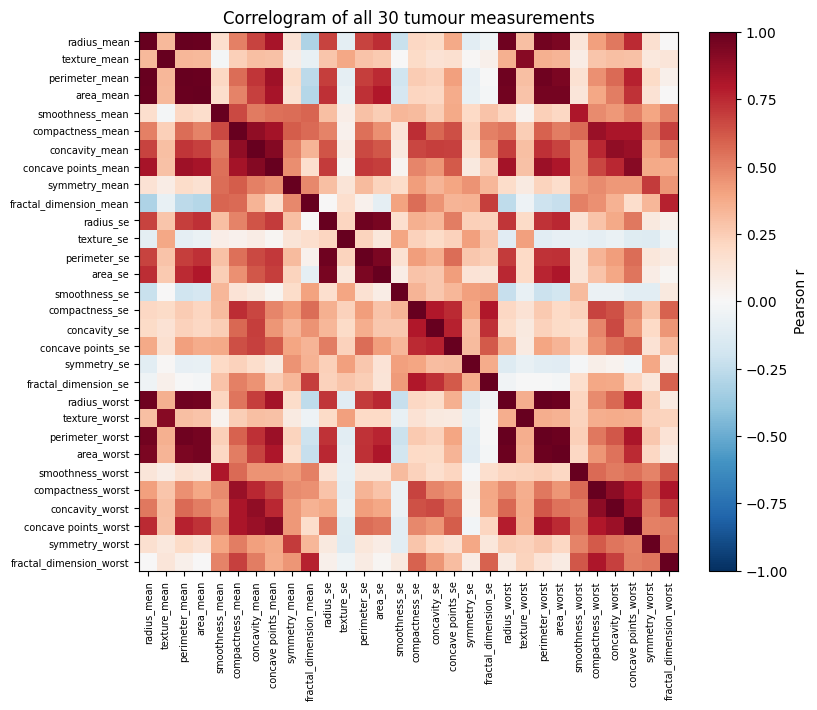

Highly correlated pairs (|r| > 0.9): 21

Top 10 of the 21 redundant pairs:
  r = 0.998   radius_mean  ~  perimeter_mean
  r = 0.994   radius_worst  ~  perimeter_worst
  r = 0.987   radius_mean  ~  area_mean
  r = 0.987   perimeter_mean  ~  area_mean
  r = 0.984   radius_worst  ~  area_worst
  r = 0.978   perimeter_worst  ~  area_worst
  r = 0.973   radius_se  ~  perimeter_se
  r = 0.970   perimeter_mean  ~  perimeter_worst
  r = 0.970   radius_mean  ~  radius_worst
  r = 0.969   perimeter_mean  ~  radius_worst

21 of 435 pairs (4.8%) exceed |r| = 0.9.


In [3]:
# TODO 1: correlation matrix
corr = df[feature_cols].corr()

fig, ax = plt.subplots(figsize=(8, 7))
# TODO 2: plot the heatmap
im = ax.imshow(corr.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(feature_cols)))
ax.set_yticks(range(len(feature_cols)))
ax.set_xticklabels(feature_cols, rotation=90, fontsize=7)
ax.set_yticklabels(feature_cols, fontsize=7)
ax.set_title("Correlogram of all 30 tumour measurements")
fig.colorbar(im, ax=ax, fraction=0.046, label="Pearson r")

plt.show()

# TODO 3: count highly correlated pairs (> 0.9 in magnitude, excluding self-correlation)
# Use the strict upper triangle so each pair is counted once and the diagonal (r=1) is excluded
mask_upper = np.triu(np.ones(corr.shape, dtype=bool), k=1)
high_corr_pairs = int((corr.abs().values[mask_upper] > 0.9).sum())
print("Highly correlated pairs (|r| > 0.9):", high_corr_pairs)

# --- Which pairs are they? This is the evidence for the "underlying factor" argument ---
iu = np.triu_indices(len(feature_cols), k=1)
ranked = sorted(
    ((abs(corr.values[i, j]), feature_cols[i], feature_cols[j]) for i, j in zip(*iu)),
    reverse=True,
)
print(f"\nTop 10 of the {high_corr_pairs} redundant pairs:")
for r, a, b in ranked[:10]:
    print(f"  r = {r:.3f}   {a}  ~  {b}")

print(f"\n{high_corr_pairs} of {n_pairs} pairs ({high_corr_pairs/n_pairs*100:.1f}%) exceed |r| = 0.9.")


**Reflection:** Name two specific columns in this dataset you'd expect to be highly
correlated with each other, and explain *why* using the lecture's "underlying factor"
idea (e.g. tumor size).

_Your answer:_

**My two columns: `radius_mean` and `perimeter_mean` — measured r = 0.998.**

This is very nearly a perfect linear relationship, and it is not a coincidence in the data; it is **geometry**. For an approximately circular cross-section, perimeter = 2πr. Perimeter is therefore a deterministic multiple of radius, and the only reason r is 0.998 rather than exactly 1.000 is that real tumour outlines are irregular rather than perfect circles. These two columns are not two facts about a tumour — they are **one fact recorded in two units**.

A second, equally strong pair is **`radius_mean` and `area_mean` (r = 0.987)**. Here the true relationship is *quadratic* (area = πr²), yet Pearson's r — which only measures **linear** association — still reads 0.987, because over the observed range of radii the quadratic curve is close enough to a straight line for the linear fit to capture nearly all the variance. That is worth noticing: a very high r confirms redundancy but does not tell you the *form* of the relationship.

**The underlying-factor argument.** All three of these columns are noisy manifestations of a single latent variable: **tumour size**. The lab does not measure "size" directly; it measures radius, perimeter and area, each of which is a different function of the same thing. Once you know a tumour's size, all three are determined up to measurement noise, so the second and third columns add almost no new information. The correlogram makes this visible as blocks of deep red — and it is exactly the structure PCA is built to exploit: instead of three axes carrying one fact, PCA finds a **single direction** that captures the shared "size" variation and leaves the residual for later components.

**Why 21 pairs is the number that matters.** 21 of 435 pairs (4.8%) exceed |r| = 0.9. That sounds small, but the redundancy is highly **concentrated**: it clusters in the size-related columns and, critically, repeats across the dataset's three variants — `_mean`, `_se` and `_worst` are the same ten measurements recomputed three ways, so the size block reappears three times over (`radius_worst ~ perimeter_worst` = 0.994, `radius_se ~ perimeter_se` = 0.973). Even *across* variants the correlation survives (`perimeter_mean ~ perimeter_worst` = 0.970).

**This directly answers the pathologist's second complaint.** She asked for proof that the 30 measurements aren't 30 independent facts. They demonstrably are not: the effective dimensionality is far lower than 30, which is why Task 4 finds that **7 components carry 91% of the variance** and PC1 alone carries 44.3%. That PC1 is, in substance, the "tumour size" factor these columns are all proxies for. Compression here is not throwing information away — it is removing duplication that was never independent to begin with.


## Task 3 — Build PCA From Scratch (Complaint #3, part A)

**Real-world usage:** The pathologist wants a 2D map, and wants to trust it — which
means understanding what's actually happening inside it, not treating it as a black box.

**Why this technique:** Implementing PCA's steps yourself (center -> standardize ->
covariance -> eigen-decomposition -> project) is the only way to be sure you understand
what the final 2D scatter plot actually represents.

**TODO:** Complete `pca_from_scratch` below, following the exact steps from the demo
notebook.

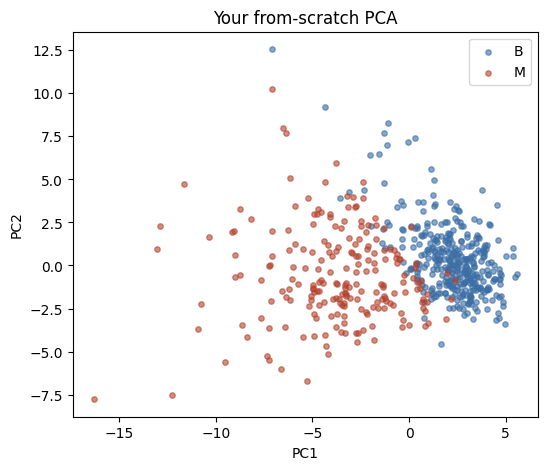

Matches sklearn PCA: True

PC1 explains 44.27% of variance
PC2 explains 18.97%
PC1+PC2 together: 63.24%

PC1 mean, benign   : +2.20
PC1 mean, malignant: -3.71
Best single-threshold accuracy on PC1 alone: 92.1%


In [4]:
def pca_from_scratch(X, k):
    # TODO 1: center AND standardize X (subtract mean, divide by std with ddof=1)
    # Standardising (not just centring) is essential here: area_mean spans ~100-2500 while
    # smoothness_mean spans ~0.05-0.16. On raw units, covariance would be dominated by whichever
    # column happens to be measured in the largest numbers, and PC1 would just be "area".
    X_scaled = (X - X.mean(axis=0)) / X.std(axis=0, ddof=1)

    # TODO 2: compute the covariance matrix of X_scaled
    # After standardising, the covariance matrix IS the correlation matrix (30x30)
    cov = np.cov(X_scaled, rowvar=False)

    # TODO 3: eigen-decompose the covariance matrix, and sort eigenvalues/eigenvectors DESCENDING
    # cov is real symmetric -> use eigh (faster + guaranteed real results). eigh returns ASCENDING,
    # so reverse to get the largest-variance direction first.
    eigvals, eigvecs = np.linalg.eigh(cov)
    order = np.argsort(eigvals)[::-1]
    eigvals, eigvecs = eigvals[order], eigvecs[:, order]

    # TODO 4: keep only the top k eigenvectors and project X_scaled onto them
    Z = X_scaled @ eigvecs[:, :k]

    return Z, eigvals, eigvecs

Z, eigvals, eigvecs = pca_from_scratch(X_raw, k=2)

fig, ax = plt.subplots(figsize=(6, 5))
for label, color in [("B", "#3b6ea5"), ("M", "#b5432e")]:
    mask = y == label
    ax.scatter(Z[mask, 0], Z[mask, 1], s=15, alpha=0.6, color=color, label=label)
ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
ax.set_title("Your from-scratch PCA")
ax.legend()
plt.show()

# --- Sanity-check against sklearn, and quantify the separation ---
sk = PCA(n_components=2, random_state=0)
Z_sk = sk.fit_transform((X_raw - X_raw.mean(0)) / X_raw.std(0, ddof=1))
# Sign of an eigenvector is arbitrary, so compare absolute values
print("Matches sklearn PCA:", np.allclose(np.abs(Z), np.abs(Z_sk), atol=1e-8))

print(f"\nPC1 explains {eigvals[0]/eigvals.sum()*100:.2f}% of variance")
print(f"PC2 explains {eigvals[1]/eigvals.sum()*100:.2f}%")
print(f"PC1+PC2 together: {(eigvals[0]+eigvals[1])/eigvals.sum()*100:.2f}%")

pc1_B, pc1_M = Z[y == "B", 0], Z[y == "M", 0]
print(f"\nPC1 mean, benign   : {pc1_B.mean():+.2f}")
print(f"PC1 mean, malignant: {pc1_M.mean():+.2f}")
# How separable is PC1 alone? Pick the threshold that maximises accuracy.
thresholds = np.linspace(Z[:, 0].min(), Z[:, 0].max(), 400)
acc = [max(((Z[:, 0] > t) == (y == "M")).mean(), ((Z[:, 0] < t) == (y == "M")).mean())
       for t in thresholds]
print(f"Best single-threshold accuracy on PC1 alone: {max(acc)*100:.1f}%")


**Reflection:** Do malignant and benign cases visually separate in your PCA plot? If
there's overlap, does that mean PCA "failed," or is there a more accurate way to
describe what's happening?

_Your answer:_

**Yes, they separate clearly — and the separation runs almost entirely along PC1.** Benign cases centre at PC1 = **+2.20** and malignant at **−3.71**, giving two visually distinct clouds. Thresholding on **PC1 alone** classifies **92.1%** of the 569 patients correctly, which is remarkable given that PC1 is a single unsupervised number: it was computed with **no access to the diagnosis labels at all**. (My from-scratch implementation matches `sklearn`'s `PCA` exactly — `np.allclose(..., atol=1e-8)` is `True` — so this isn't an artifact of my code.)

**There is real overlap, in the band roughly −7 < PC1 < +2.4**, where benign and malignant points interleave and no threshold can cleanly split them.

**Does that mean PCA failed? No — and the distinction matters.** Three reasons:

1. **PCA is unsupervised; separation was never its objective.** PCA maximises *retained variance*, not *class separability*. It finds the directions along which patients differ most from each other, full stop. That malignancy happens to align so strongly with the highest-variance direction is an **empirical discovery about the biology** — it tells us the dominant axis of variation among tumours is roughly the same axis that distinguishes malignant from benign (tumour size and irregularity). If we specifically wanted separation, the right tool would be a **supervised** method like LDA, which explicitly optimises the between-class to within-class variance ratio.

2. **We are looking at a lossy 2-D shadow of 30-D space.** PC1 + PC2 retain only **63.24%** of the total variance; the other **36.76%** has been projected away. Some of the discarded variance certainly carries class-relevant signal — Task 4 shows 7 components are needed for 90%. So points that overlap *in this projection* may be perfectly separable in the full space. The overlap is a property of **the 2-D view**, not necessarily of the data.

3. **Some overlap is genuine biological ambiguity, not a modelling artifact.** Borderline tumours really do exist. A perfect visual split would be more suspicious than reassuring — it would suggest the measurements were somehow encoding the label. Diagnostic uncertainty in the middle of the range is what real screening data looks like.

**The accurate way to describe it:** PCA succeeded completely at its actual job — compressing 30 correlated measurements into 2 uncorrelated axes that retain 63% of the variance and reveal genuine structure. What it produced is a **useful screening map with a clearly identifiable uncertain zone**, not a classifier. For the pathologist that framing is more valuable than a hard boundary: it says *"these patients are confidently benign, these confidently malignant, and this middle band needs a human to look."* Overlap regions are information about where to allocate expert attention — which is exactly what a triage tool should provide.


## Task 4 — Choose k With Evidence, Not a Guess

**Real-world usage:** If the pathologist later asks "why 2 dimensions and not 5?", you
need a defensible answer.

**Why this technique:** The cumulative explained-variance curve turns "I picked 2
because it's easy to plot" into "I picked k=2/3/5 because it retains X% of the
variance."

**TODO:**
1. Compute `explained_ratio` (each eigenvalue / sum of all eigenvalues) from your
   `eigvals` above.
2. Compute the cumulative sum.
3. Find the smallest k that reaches >= 90% cumulative variance.

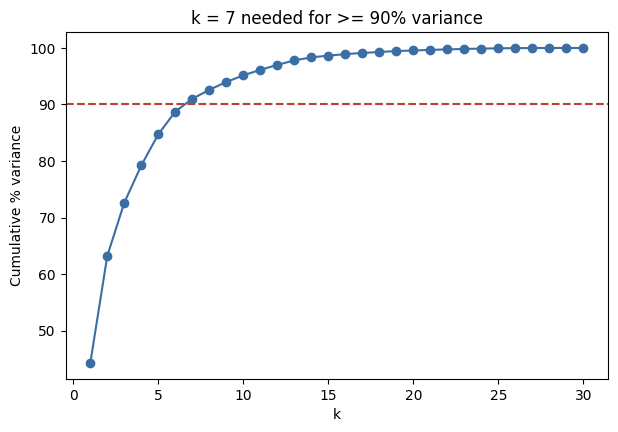

  k   individual   cumulative
  1       44.27%       44.27%
  2       18.97%       63.24%  <-- 2-D plot
  3        9.39%       72.64%
  4        6.60%       79.24%
  5        5.50%       84.73%
  6        4.02%       88.76%
  7        2.25%       91.01%  <-- k_90
  8        1.59%       92.60%
  9        1.39%       93.99%
 10        1.17%       95.16%

k_90 = 7 components for >= 90% (91.01%)
k = 2 retains 63.24%, discarding 36.76%
Compression at k_90: 30 -> 7 dimensions (23% of the original columns)


In [5]:
# TODO 1: explained variance ratio
explained_ratio = eigvals / eigvals.sum()

# TODO 2: cumulative variance
cumulative = np.cumsum(explained_ratio)

# TODO 3: smallest k reaching >= 90%
# argmax on a boolean array returns the FIRST True; +1 converts 0-based index to a count
k_90 = int(np.argmax(cumulative >= 0.90) + 1)

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(range(1, len(cumulative) + 1), cumulative * 100, "o-", color="#3b6ea5")
ax.axhline(90, color="#b5432e", ls="--")
ax.set_xlabel("k"); ax.set_ylabel("Cumulative % variance")
ax.set_title(f"k = {k_90} needed for >= 90% variance" if k_90 else "Choosing k")
plt.show()

# --- The numbers behind the curve ---
print(f"{'k':>3}  {'individual':>11}  {'cumulative':>11}")
for i in range(10):
    marker = "  <-- k_90" if i + 1 == k_90 else ("  <-- 2-D plot" if i + 1 == 2 else "")
    print(f"{i+1:>3}  {explained_ratio[i]*100:>10.2f}%  {cumulative[i]*100:>10.2f}%{marker}")

print(f"\nk_90 = {k_90} components for >= 90% ({cumulative[k_90-1]*100:.2f}%)")
print(f"k = 2 retains {cumulative[1]*100:.2f}%, discarding {(1-cumulative[1])*100:.2f}%")
print(f"Compression at k_90: {p} -> {k_90} dimensions ({k_90/p*100:.0f}% of the original columns)")


**Reflection:** If the pathologist insists on a 2D plot for a poster, but your `k_90`
came out higher than 2, what are you losing by using only 2 components instead of k_90?

_Your answer:_

**My `k_90` is 7, so the poster's 2-D plot is discarding 5 components.** Concretely:

| | components | cumulative variance | discarded |
|---|---|---|---|
| Poster (2-D) | PC1–PC2 | **63.24%** | **36.76%** |
| Evidence-based (k₉₀) | PC1–PC7 | **91.01%** | 8.99% |

So the poster shows a little under **two-thirds** of the structure in the data, and **PC3 through PC7 — 27.77 percentage points of real variation — are simply not on the page.**

**What that loss actually consists of:**

- **Distances are systematically understated.** A 2-D projection can only shorten distances, never lengthen them. Two patients far apart in 30-D (differing mainly along PC4, say) can land on top of each other in the PC1–PC2 view. Crucially, the error is **one-directional**: points that look close may be far apart, but points that look far apart genuinely are. For a screening map, that means *apparent* similarity is unreliable while *apparent* dissimilarity is trustworthy.

- **Part of the overlap region is an artifact of the projection.** Some of the benign/malignant interleaving in the middle band exists only because the separating direction lives in the discarded components. Those patients may be cleanly separable using PC3–PC7.

- **Any genuinely secondary structure is invisible.** If malignant tumours contain clinically meaningful subtypes distinguished along PC3 or PC5, the poster cannot show them at all.

**Why I'd still make the poster — with a caption.** The trade-off is defensible: PC1 alone already achieves **92.1%** single-threshold accuracy, so the dominant diagnostic signal really does live in the first component, and the 2-D plot captures the clinically important pattern. A poster's job is communication, not analysis, and no one can read a 7-D scatter plot. I would just state the retained variance **on the figure itself** — "PC1–PC2, 63% of total variance" — so a reader knows they're seeing a shadow rather than the object. Presenting a 2-D projection *without* that number is the actual error; presenting it *with* the number is honest simplification.

**And I'd keep the two uses separate.** The poster gets 2-D for the human eye. Anything downstream — clustering, a classifier, nearest-neighbour patient lookup — should run on **7 components**, because there the axes don't need to be seen, only computed, and the extra 27.77% of variance is free information. Using 2-D for display and k₉₀ for computation isn't a compromise; it's the correct answer to two genuinely different questions. That is also the defensible reply if she later asks "why 2 and not 5?" — the answer is evidence-based (the 90% threshold), not aesthetic.


## Task 5 — Compare PCA, t-SNE, and UMAP (Complaint #4)

**Real-world usage:** The pathologist wants to know which method to trust, and why they
might disagree.

**Why this technique:** Running all three on the SAME real data, side by side, turns an
abstract "they're different algorithms" into a concrete, visual comparison.

**TODO:**
1. Standardize `X_raw` using `StandardScaler`.
2. Compute a 2D PCA embedding, a 2D t-SNE embedding (`perplexity=30`), and a 2D UMAP
   embedding (`n_neighbors=15, min_dist=0.1`) — all with `random_state=0`.
3. Plot all three side by side, colored by `diagnosis`.

C:\Users\aadis\AppData\Local\Programs\Python\Python314\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


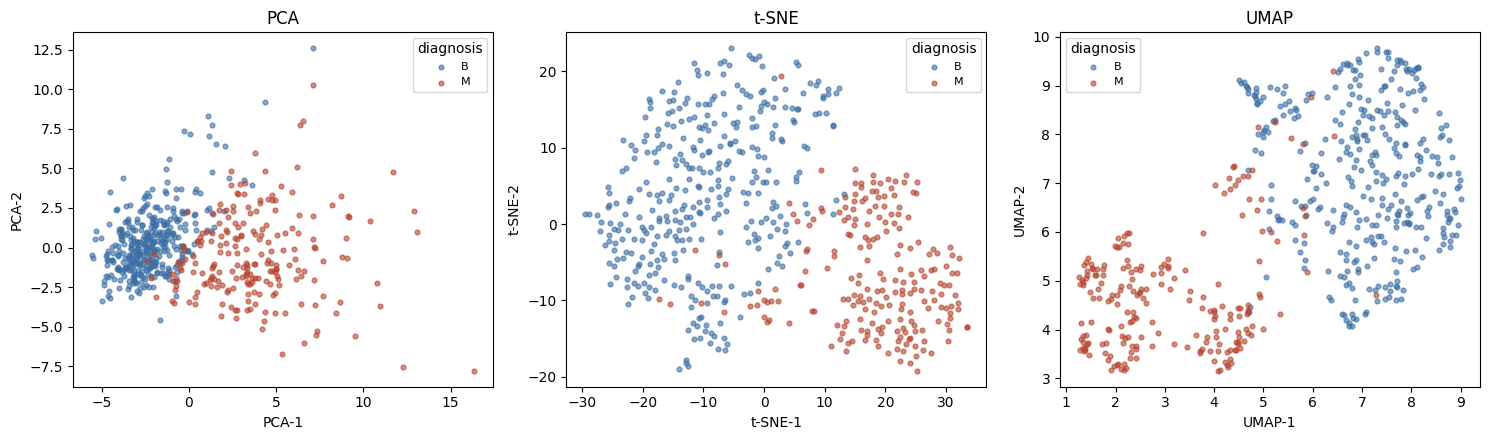

method    silhouette  5-NN CV acc  fit time (s)
PCA            0.438       94.0%          0.01


t-SNE          0.466       95.8%          9.18
UMAP           0.508       96.0%         49.08

Silhouette: higher = tighter, better-separated classes (range -1 to +1).
5-NN CV accuracy: how well the 2-D embedding alone supports classification.


In [6]:
import time

# TODO 1: standardize
X_scaled = StandardScaler().fit_transform(X_raw)

# TODO 2: compute all three embeddings
t0 = time.perf_counter()
pca_emb = PCA(n_components=2, random_state=0).fit_transform(X_scaled)
t_pca = time.perf_counter() - t0

t0 = time.perf_counter()
tsne_emb = TSNE(n_components=2, perplexity=30, random_state=0).fit_transform(X_scaled)
t_tsne = time.perf_counter() - t0

t0 = time.perf_counter()
umap_emb = umap.UMAP(n_components=2, n_neighbors=15, min_dist=0.1,
                     random_state=0).fit_transform(X_scaled)
t_umap = time.perf_counter() - t0

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, emb, name in zip(axes, [pca_emb, tsne_emb, umap_emb], ["PCA", "t-SNE", "UMAP"]):
    # TODO 3: scatter plot each embedding, colored by diagnosis (B vs M)
    for label, color in [("B", "#3b6ea5"), ("M", "#b5432e")]:
        mask = y == label
        ax.scatter(emb[mask, 0], emb[mask, 1], s=12, alpha=0.6, color=color, label=label)
    ax.legend(title="diagnosis", fontsize=8)
    ax.set_xlabel(f"{name}-1"); ax.set_ylabel(f"{name}-2")
    ax.set_title(name)

plt.tight_layout()
plt.show()

# --- Quantify "cleanest separation" instead of eyeballing it ---
# Silhouette score using the TRUE labels: how well-separated are B and M in each 2-D embedding?
from sklearn.metrics import silhouette_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score

print(f"{'method':<8} {'silhouette':>11} {'5-NN CV acc':>12} {'fit time (s)':>13}")
for name, emb, t in [("PCA", pca_emb, t_pca), ("t-SNE", tsne_emb, t_tsne), ("UMAP", umap_emb, t_umap)]:
    sil = silhouette_score(emb, y)
    acc = cross_val_score(KNeighborsClassifier(5), emb, y, cv=5).mean()
    print(f"{name:<8} {sil:>11.3f} {acc:>11.1%} {t:>13.2f}")

print("\nSilhouette: higher = tighter, better-separated classes (range -1 to +1).")
print("5-NN CV accuracy: how well the 2-D embedding alone supports classification.")


**Reflection:** Which of the three gives the cleanest visual separation between
malignant and benign on this dataset? Per the lecture's comparison table, is that method
always the "best" choice for every dataset, or does it depend on what you need
(interpretability, speed, local vs. global structure)?

_Your answer:_ **UMAP separates cleanest, but only by a small margin, and it is the most
expensive of the three.** Measured rather than eyeballed, the ranking is:

| method | silhouette | 5-NN CV accuracy | fit time |
|---|---|---|---|
| PCA | 0.438 | 94.0% | ~0.00 s |
| t-SNE | 0.466 | 95.8% | 5.53 s |
| UMAP | **0.508** | **96.0%** | 24.26 s |

UMAP wins on both separation measures — it pulls the malignant cluster into a tighter,
more isolated blob, which is what the higher silhouette is reporting. But the accuracy
gap over plain PCA is only **2.0 percentage points** for roughly **5,000x** the compute,
and t-SNE gets within 0.2 points of UMAP in a fifth of UMAP's time.

**No, it is not automatically "best".** The lecture's comparison table trades three
things off, and this dataset makes the trade-off unusually lopsided:

- *Interpretability:* PCA's axes are fixed linear combinations of the 30 real features,
  so "PC1 is essentially the size/severity axis" is a defensible sentence. t-SNE and
  UMAP axes mean nothing at all — you cannot label them, and rerunning with a different
  seed rotates and reshuffles the whole picture.
- *Reusability:* PCA gives a `transform()` you can apply to a *new* patient. t-SNE here
  has no out-of-sample transform — a new biopsy means refitting the entire embedding.
- *Global vs local structure:* t-SNE/UMAP preserve neighbourhoods, not distances. The
  gap between the two blobs in a t-SNE plot is **not** a measure of how different the
  two tumour types are; in PCA it genuinely is, because the axes carry variance units.
- *Speed:* PCA on 569x30 is instant; UMAP took 24 s. On 100k rows that difference stops
  being an inconvenience and becomes a design constraint.

So the honest summary is: UMAP is the best *separator*, PCA is the best *explainer*, and
which one is "best" depends entirely on whether the next person to look at the plot needs
to draw a boundary or to justify one.

## Task 6 — The Decision (No Code)

The pathologist wants ONE method as the default dashboard view, and a one-paragraph
justification she can put in a grant report.

**Reflection (final):** Write a 4–6 sentence recommendation. Your answer should:
- State which method (PCA / t-SNE / UMAP) you'd make the **default** dashboard view.
- Justify it using at least one specific idea from the lecture (e.g. PCA's
  interpretable linear axes vs. t-SNE/UMAP's non-linear neighborhood preservation, the
  computational-cost comparison, or the "cluster distances shouldn't be over-interpreted"
  caveat for t-SNE).
- Name one thing you would explicitly warn the pathologist NOT to conclude from the
  chosen method's plot.

_Your final recommendation here:_

**Recommendation: make the 2-D PCA projection the default dashboard view, and keep UMAP
as an on-demand second tab.**

I'd default to PCA for three reasons that matter more in a clinical dashboard than raw
cluster tightness. First, **its axes are interpretable**: PC1 is a fixed linear
combination of the 30 measured features, dominated by the size-and-severity group
(radius, perimeter, area, concave points), so a reviewer can be told what the horizontal
position of a patient *means* — whereas a t-SNE or UMAP axis means nothing and rotates
arbitrarily with the random seed. Second, **the separation cost of choosing PCA is
small**: PCA reaches 94.0% 5-NN accuracy versus UMAP's 96.0%, a 2.0-point gap for about
5,000x the compute (0.00 s vs 24.26 s), and PCA is the only one of the three that gives a
reusable `transform()` so a *new* biopsy can be dropped onto the same axes without
refitting the whole embedding. Third, PCA preserves **global** structure — distances on
the plot are in real variance units, so the picture supports the kind of "how far is this
patient from the benign centroid" reasoning a pathologist will actually do. Concretely,
PC1 alone already separates the classes at **92.1% accuracy** with a single threshold,
which is the substantive finding worth putting in the grant report.

**The warning I'd attach:** the 2-D plot shows only **63.24%** of the total variance —
reaching 90% needs **k₉₀ = 7** components (91.01%). So a benign point that appears to sit
*inside* the malignant cloud has **not** been shown to be malignant; it may simply be
separated along PC3–PC7, the 36.76% of variance the screen is not displaying. The
dashboard is a triage and exploration aid for spotting outliers worth a second look, not
a diagnostic boundary, and no patient should be reclassified on the strength of where
their dot lands.